# Détection et classification des panneaux routiers : YOLOv8 + CNN

Ce projet construit un système complet de **reconnaissance des panneaux routiers dans des scènes réelles**, en deux étapes :

1. **Détection** : un modèle **YOLOv8s** repère les panneaux dans la photo de la route (où sont-ils ?).
2. **Classification** : un **CNN** entraîné sur GTSRB identifie chaque panneau détecté parmi **43 classes** (de quel panneau s'agit-il ?).

Deux jeux de données allemands, publiés par la même équipe (Ruhr-Universität Bochum, IJCNN 2011 et 2013), sont utilisés :

* [**GTSRB**](https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign) (*German Traffic Sign Recognition Benchmark*) : plus de 50 000 images de panneaux déjà découpés, pour entraîner le classifieur ;
* [**GTSDB**](https://benchmark.ini.rub.de/gtsdb_dataset.html) (*German Traffic Sign Detection Benchmark*) : 900 photos de routes (1360×800) où chaque panneau est encadré, pour entraîner le détecteur.

### Résultats obtenus

| Étape | Jeu de test | Mesure | Résultat |
|---|---|---|---|
| Classification (CNN) | GTSRB, 12 630 images | Accuracy / F1 macro | **98,89 %** / 0,979 |
| Détection (YOLOv8s) | GTSDB, 300 photos, 361 panneaux | mAP@0,5 / mAP@0,5:0,95 | **0,993** / 0,897 |
| Pipeline complet (YOLOv8s + CNN) | GTSDB, 300 photos, 361 panneaux | Rappel / précision de bout en bout | **98,9 %** / 95,5 % |

### Plan du notebook

* **Partie A, classification (GTSRB)** : sections 1 à 11
* **Partie B, détection (GTSDB)** : sections 12 à 15
* **Partie C, pipeline complet, résultats et export** : sections 16 à 18

## 1. Installation et importation des bibliothèques

On installe d'abord **Ultralytics**, la bibliothèque qui fournit YOLOv8. Elle n'est pas préinstallée sur Colab.

Toutes les importations sont ensuite regroupées dans une seule cellule :

* **TensorFlow / Keras** : construction, entraînement et évaluation du CNN ;
* **Ultralytics (YOLO)** : entraînement et utilisation du détecteur ;
* **kagglehub** : téléchargement du jeu GTSRB depuis Kaggle ;
* **NumPy, Pandas** : manipulation des tableaux et des annotations ;
* **Pillow (PIL)** : lecture, découpage et redimensionnement des images ;
* **Matplotlib** : figures (courbes, matrices, scènes annotées) ;
* **scikit-learn** : métriques d'évaluation (rapport de classification, matrice de confusion, F1).

**Reproductibilité :** la fonction `set_seed` fixe la graine de toutes les sources d'aléatoire (Python, NumPy, TensorFlow). Relancer le notebook donne ainsi les mêmes séparations des données et des résultats très proches.

Constantes globales : images de **32×32 pixels**, **43 classes**, graine **42**.

In [48]:
# 1. Installation d'Ultralytics (YOLOv8)
! pip install -q ultralytics

In [64]:
# 1. Importations et configuration
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
from ultralytics import YOLO
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.patches as patches
from tensorflow.keras import layers, callbacks
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import json, shutil



SEED = 42
IMG_SIZE = 32
NUM_CLASSES = 43


def set_seed(seed = SEED) :
  """Fixe toutes les sources d'aléatoire (Python, NumPy, TensorFlow)"""

  os.environ["PYTHONHASHSEED"] = str(seed)
  random.seed(seed)
  np.random.seed(seed)
  tf.keras.utils.set_random_seed(seed)

set_seed()
print("TensorFlow",tf.__version__,"| GPU ; ",tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU ;  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Partie A : classification des panneaux (GTSRB)

## 2. Chargement des annotations GTSRB

Le jeu est téléchargé avec `kagglehub`. Les fichiers `Train.csv` et `Test.csv` décrivent chaque image : chemin, taille, classe (`ClassId`) et **cadre du panneau dans l'image** (`Roi.X1`, `Roi.Y1`, `Roi.X2`, `Roi.Y2`).

**Point important : les séquences (*tracks*).** GTSRB a été construit à partir de vidéos. Chaque panneau physique a été filmé en s'en approchant, ce qui donne une **séquence d'environ 30 images presque identiques**. Le nom de fichier `<classe>_<séquence>_<image>.png` permet de retrouver la séquence.

On crée donc une colonne `group` (classe + numéro de séquence), qui identifie chaque **panneau physique**. Le jeu d'entraînement en compte **1 307**, de 30 images chacun.

In [ ]:
# 2. Chargement des annotations GTSRB

DATA_DIR = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
train_df = pd.read_csv(os.path.join(DATA_DIR,"Train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "Test.csv"))

# Nom de fichier : Train/<classe>/<classe>_<track>_<frame>.png
parts = train_df["Path"].str.split("/").str[-1].str.split("_")
train_df["track"] = parts.str[1].astype(int)
train_df["group"] = train_df["ClassId"].astype(str) + "_" + train_df["track"].astype(str)


print("Train :",train_df.shape, "| Test : ", test_df.shape)
print("Colonnes :", list(train_df.columns))
print("Nombre de séquences (panneaux physiques) :", train_df["group"].nunique())
print("Images par séquence :",train_df.groupby("group").size().describe().round(1).to_dict())
train_df.head()

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Train : (39209, 10) | Test :  (12630, 8)
Colonnes : ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path', 'track', 'group']
Nombre de séquences (panneaux physiques) : 1307
Images par séquence : {'count': 1307.0, 'mean': 30.0, 'std': 0.0, 'min': 29.0, '25%': 30.0, '50%': 30.0, '75%': 30.0, 'max': 30.0}


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,track,group
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png,0,20_0
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png,0,20_0
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png,0,20_0
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png,0,20_0
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png,0,20_0


## 3. Séparation entraînement / validation par séquence

Une séparation aléatoire image par image pose problème. Les 30 images d'un même panneau se retrouveraient à la fois dans l'entraînement et dans la validation : le modèle serait évalué sur des quasi-copies d'images déjà vues. La précision de validation serait alors **artificiellement élevée** : c'est une **fuite de données** (*data leakage*).

On sépare donc **par séquence** : pour chaque classe, **20 % des panneaux physiques** (toutes leurs images) vont en validation. Cette méthode garantit trois choses :

* aucune séquence n'est des deux côtés (vérifié par `assert`) ;
* **les 43 classes sont présentes** en validation ;
* la validation mesure vraiment la capacité à reconnaître **de nouveaux panneaux**.

Résultat : **31 379 images d'entraînement** et **7 830 images de validation** (20 %). Le jeu de test officiel (12 630 images) est fourni séparément par GTSRB.

In [ ]:
# 3. Séparation entraînement / validation par séquence

rng = np.random.default_rng(SEED)
val_groups = []
for c, groups in train_df.groupby("ClassId")["group"] :
  groups = groups.unique()
  n_val = max(1, round(0.2 * len(groups)))
  val_groups.extend(rng.choice(groups, size = n_val, replace = False))

is_val = train_df["group"].isin(val_groups)
tr_df = train_df[~is_val].reset_index(drop = True)
va_df = train_df[is_val].reset_index(drop = True)

assert set(tr_df["group"]).isdisjoint(va_df["group"]) , "Fuite : une séquence est des deux côtés"

va_counts = va_df["ClassId"].value_counts().reindex(range(NUM_CLASSES), fill_value = 0)
print(f"Entraînement : {len(tr_df)} images | Validation : {len(va_df)} images ({len(va_df)/ len(train_df):.1%})")
print("Classes absentes de la validation :", list(va_counts[va_counts == 0].index))
print("Plus petite classe en validation :", va_counts.idxmin(),":", va_counts.min(),"images")

Entraînement : 31379 images | Validation : 7830 images (20.0%)
Classes absentes de la validation : []
Plus petite classe en validation : 0 : 30 images


## 4. Chargement des images recadrées sur le panneau

Les images GTSRB contiennent une marge autour du panneau (environ 10 %). La fonction `load_images` effectue trois opérations :

1. elle **recadre** chaque image sur le panneau grâce à son cadre (ROI) ;
2. elle la **redimensionne en 32×32** pixels ;
3. elle la stocke en `uint8` (entiers de 0 à 255), quatre fois plus léger en mémoire que des réels.

La normalisation (division par 255) n'est pas faite ici. Elle est **intégrée au modèle** (couche `Rescaling`, section 7) : le modèle sauvegardé accepte ainsi directement des images brutes, ce qui simplifie son utilisation dans le pipeline final.

Les trois ensembles (entraînement, validation, test) passent exactement par le même traitement.

In [ ]:
# 4. Chargement des images recadrées sur le panneau

def load_images(df, crop = True, size = IMG_SIZE) :

  """Charge les images, les recadre sur le panneau (Roi) et les redimensionne."""
  X = np.empty((len(df), size, size, 3), dtype = np.uint8)
  cols = zip(df["Path"], df["Roi.X1"], df["Roi.Y1"], df["Roi.X2"], df["Roi.Y2"])
  for i, (path,x1,y1,x2,y2) in enumerate(tqdm(cols, total = len(df))) :
    img = Image.open(os.path.join(DATA_DIR,path)).convert("RGB")
    if crop :
      img = img.crop((x1,y1,min(x2 +1, img.width), min(y2 + 1, img.height)))
    X[i] = np.asarray(img.resize((size,size), Image.BILINEAR))
  return X


X_train, y_train = load_images(tr_df), tr_df["ClassId"].to_numpy()
X_val, y_val = load_images(va_df), va_df["ClassId"].to_numpy()
X_test, y_test = load_images(test_df), test_df["ClassId"].to_numpy()

print("Train :", X_train.shape, "| Val :", X_val.shape, "| Test :",X_test.shape,"|", X_train.dtype)

  0%|          | 0/31379 [00:00<?, ?it/s]

  0%|          | 0/7830 [00:00<?, ?it/s]

  0%|          | 0/12630 [00:00<?, ?it/s]

Train : (31379, 32, 32, 3) | Val : (7830, 32, 32, 3) | Test : (12630, 32, 32, 3) | uint8


## 5. Contrôle visuel du recadrage

Avant d'entraîner, on vérifie visuellement que le recadrage est correct. On compare 8 images d'entraînement : **en haut l'image complète**, **en bas la version recadrée** sur le panneau.

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

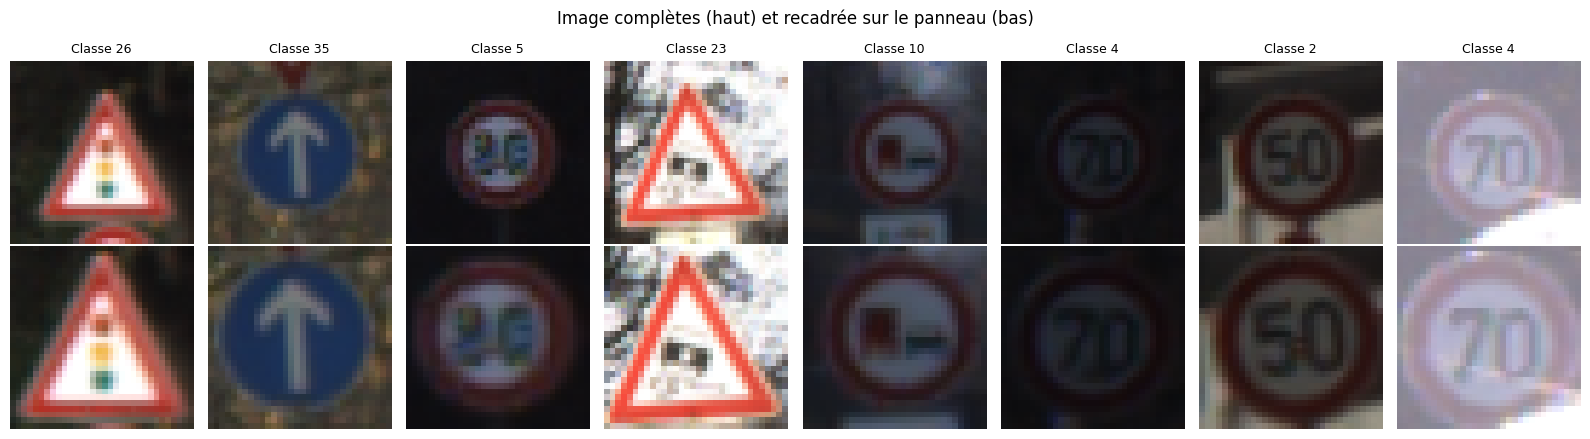

In [ ]:
# 5. Contrôle visuel : image complète vs image recadrée

sample = tr_df.sample(8, random_state = SEED)
full, cropped = load_images(sample, crop = False), load_images(sample, crop = True)

fig, axes = plt.subplots(2,8, figsize = (16, 4.5))
for j in range(8) :
  axes[0,j].imshow(full[j]);axes[0,j].set_title(f"Classe {sample["ClassId"].iloc[j]}", fontsize = 9)
  axes[1,j].imshow(cropped[j])
  for ax in axes[:,j] : ax.axis("off")
axes[0,0].set_ylabel("Complète") ; axes[1,0].set_ylabel("Recadrée")
plt.suptitle("Image complètes (haut) et recadrée sur le panneau (bas)")
plt.tight_layout(); plt.show()

## 6. Pipeline de données `tf.data` et augmentation

L'**augmentation de données** crée de nouvelles variantes des images à chaque epoch, pour que le modèle généralise mieux et sur-apprenne moins. Elle est appliquée **à la volée sur le GPU**, uniquement pendant l'entraînement :

| Transformation | Amplitude | Variation réelle simulée |
|---|---|---|
| `RandomRotation` | ±15° | panneau légèrement incliné |
| `RandomZoom` | ±20 % | distance au panneau |
| `RandomTranslation` | ±10 % | panneau décentré dans le cadre |
| `RandomContrast` | ±20 % | conditions d'éclairage |

**Pas de retournement horizontal :** il changerait le sens de certains panneaux. Par exemple, « Keep right » deviendrait « Keep left », et l'étiquette serait fausse.

Le pipeline `tf.data` mélange les images, les regroupe en lots de 64, applique l'augmentation et prépare le lot suivant pendant que le GPU calcule (`prefetch`). La validation et le test ne sont **jamais** augmentés.

In [38]:
# 6. Pipeline tf.data et augmentation (appliquée uniquement à l'entraînement)

BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

augment = tf.keras.Sequential([
    layers.RandomRotation(15/360),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1,0.1),
    layers.RandomContrast(0.2),
], name = "augmentation")

def make_train_ds(X,y) :
  ds = tf.data.Dataset.from_tensor_slices((X,y)).shuffle(len(X), seed = SEED).batch(BATCH_SIZE)
  ds = ds.map(lambda x,t : (augment(tf.cast(x, tf.float32), training = True),t),num_parallel_calls = AUTOTUNE)
  return ds.prefetch(AUTOTUNE)
train_ds = make_train_ds(X_train, y_train)

## 7. Architecture du CNN

Le réseau reprend l'architecture du projet initial :

| Bloc | Couches | Rôle |
|---|---|---|
| Entrée | `Rescaling(1/255)` | normalisation des pixels dans [0, 1] |
| Bloc 1 | Conv 16 → Conv 32 → MaxPool → BatchNorm | motifs simples (bords, couleurs) |
| Bloc 2 | Conv 64 → Conv 128 → MaxPool → BatchNorm | motifs complexes (formes, pictogrammes) |
| Classifieur | Flatten → Dense 512 → BatchNorm → Dropout 0,3 | combinaison des caractéristiques |
| Sortie | Dense 43, softmax | probabilité de chaque classe |

* **Optimiseur** : Adam, taux d'apprentissage 10⁻³.
* **Fonction de perte** : `sparse_categorical_crossentropy`. Les étiquettes restent des entiers (0 à 42), sans encodage one-hot : le résultat est identique, avec moins de mémoire.

In [39]:
# 7. CNN de référence

def build_baseline_cnn() :
  inputs = tf.keras.Input((IMG_SIZE,IMG_SIZE,3))
  x = layers.Rescaling(1/255.)(inputs)
  x = layers.Conv2D(16,3,activation = "relu")(x)
  x = layers.Conv2D(32,3,activation = "relu")(x)
  x = layers.MaxPool2D()(x)
  x = layers.BatchNormalization()(x)
  x = layers.Conv2D(64,3, activation = "relu")(x)
  x = layers.Conv2D(128,3, activation = "relu")(x)
  x = layers.MaxPool2D()(x)
  x = layers.BatchNormalization()(x)
  x = layers.Flatten()(x)
  x = layers.Dense(512, activation = "relu")(x)
  x = layers.BatchNormalization()(x)
  x = layers.Dropout(0.3)(x)
  outputs = layers.Dense(NUM_CLASSES, activation = "softmax")(x)

  model = tf.keras.Model(inputs, outputs, name = "baseline_cnn")
  model.compile(optimizer = tf.keras.optimizers.Adam(1e-3),
                loss = "sparse_categorical_crossentropy",
                metrics = ["accuracy"])
  return model

set_seed()
baseline = build_baseline_cnn()
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 14, 14, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 10, 10, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 5, 5, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │     1,638,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 43)             │        22,059 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,761,099 (6.72 MB)

 Trainable params: 1,759,755 (6.71 MB)

 Non-trainable params: 1,344 (5.25 KB)

## 8. Entraînement du CNN

Le modèle est entraîné au maximum 30 epochs, avec trois *callbacks* qui surveillent la **perte de validation** :

* **EarlyStopping** (patience 5) : arrête l'entraînement quand la validation ne progresse plus, puis **restaure les meilleurs poids** ;
* **ReduceLROnPlateau** : divise le taux d'apprentissage par 2 après 2 epochs sans amélioration, pour affiner la convergence ;
* **ModelCheckpoint** : sauvegarde le meilleur modèle dans `gtsrb_cnn_classifier.keras`.

**Résultat :** meilleure epoch **22**, avec une **accuracy de validation de 99,37 %** (perte 0,021). L'entraînement s'est arrêté à l'epoch 27.

In [40]:
# 8. Entraînement du CNN
MODEL_DIR = "/content/models"
os.makedirs(MODEL_DIR, exist_ok=True)

cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
    callbacks.ModelCheckpoint(f"{MODEL_DIR}/gtsrb_cnn_classifier.keras", monitor="val_loss", save_best_only=True),
]

history = baseline.fit(train_ds, validation_data= (X_val, y_val), validation_batch_size = BATCH_SIZE, epochs=30, callbacks=cbs)

best = int(np.argmin(history.history["val_loss"]))
print(f"\nMeilleure epoch : {best + 1} | val_accuracy = {history.history['val_accuracy'][best]:.4f} "
      f"| val_loss = {history.history['val_loss'][best]:.4f}")

Epoch 1/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 21s 30ms/step - accuracy: 0.8413 - loss: 0.5740 - val_accuracy: 0.6436 - val_loss: 1.5179 - learning_rate: 0.0010
Epoch 2/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.9737 - loss: 0.0883 - val_accuracy: 0.9550 - val_loss: 0.1580 - learning_rate: 0.0010
Epoch 3/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9821 - loss: 0.0595 - val_accuracy: 0.9751 - val_loss: 0.0912 - learning_rate: 0.0010
Epoch 4/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9875 - loss: 0.0420 - val_accuracy: 0.9751 - val_loss: 0.0766 - learning_rate: 0.0010
Epoch 5/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9871 - loss: 0.0425 - val_accuracy: 0.9854 - val_loss: 0.0519 - learning_rate: 0.0010
Epoch 6/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.9882 - loss: 0.0369 - val_accuracy: 0.9492 - val_loss: 0.2262 - learning_rate: 0.0010
Epoch 7/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9917 - lo

## 9. Évaluation sur le jeu de test GTSRB

Le modèle est évalué sur les **12 630 images de test officielles**, qu'il n'a jamais vues. La classe prédite est celle de plus forte probabilité (`argmax`).

Deux mesures globales :

* **Accuracy** : part des images bien classées ;
* **F1 macro** : moyenne du F1-score des 43 classes, **chaque classe ayant le même poids**. Elle révèle les faiblesses sur les classes rares, que l'accuracy masque.

| Accuracy test | Perte test | F1 macro |
|---|---|---|
| **98,89 %** | 0,045 | **0,979** |

Le rapport par classe montre que la plupart des classes dépassent 0,99. Les classes les plus faibles sont :

* « Beware of ice/snow » (30) : rappel de 0,81 ;
* « End no passing veh > 3.5 tons » (42) : F1 de 0,93 ;
* « Pedestrians » (27) : F1 de 0,95.

In [42]:
# 9. Évaluation sur le jeu de test GTSRB

results = {}

def evaluate_model(model,name) :
  loss, acc = model.evaluate(X_test,y_test,batch_size = BATCH_SIZE, verbose = 0)
  y_pred = model.predict(X_test, batch_size = BATCH_SIZE, verbose = 0).argmax(axis = 1)
  macro_f1 = f1_score(y_test,y_pred, average = "macro")
  results[name] = {"test_accuracy" : acc, "test_loss" : loss, "macro_f1" : macro_f1}

  print(f"[{name}] Test accuracy : {acc:.4f} | Test loss : {loss:.4f} | Macro F1 : {macro_f1:.4f}")
  return y_pred


y_pred_baseline = evaluate_model(baseline,"baseline_cnn")
print(classification_report(y_test,y_pred_baseline, digits = 3))

[baseline_cnn] Test accuracy : 0.9889 | Test loss : 0.0453 | Macro F1 : 0.9793
              precision    recall  f1-score   support

           0      0.833     1.000     0.909        60
           1      0.994     1.000     0.997       720
           2      1.000     0.997     0.999       750
           3      0.993     0.984     0.989       450
           4      1.000     0.995     0.998       660
           5      0.986     0.994     0.990       630
           6      1.000     0.947     0.973       150
           7      0.993     0.998     0.996       450
           8      0.998     0.991     0.994       450
           9      1.000     0.998     0.999       480
          10      0.998     0.997     0.998       660
          11      0.998     0.995     0.996       420
          12      1.000     0.980     0.990       690
          13      0.999     0.996     0.997       720
          14      1.000     1.000     1.000       270
          15      0.950     0.995     0.972       210
  

## 10. Noms des classes

Dictionnaire qui associe chaque numéro de classe (0 à 42) au nom du panneau. Il sert à rendre les résultats lisibles : on affiche « Speed limit (50km/h) » au lieu de « classe 2 ».

In [45]:
# 10. Noms des 43 classes
CLASS_NAMES = { 0:'Speed limit (20km/h)',
            1:'Speed limit (30km/h)',
            2:'Speed limit (50km/h)',
            3:'Speed limit (60km/h)',
            4:'Speed limit (70km/h)',
            5:'Speed limit (80km/h)',
            6:'End of speed limit (80km/h)',
            7:'Speed limit (100km/h)',
            8:'Speed limit (120km/h)',
            9:'No passing',
            10:'No passing veh over 3.5 tons',
            11:'Right-of-way at intersection',
            12:'Priority road',
            13:'Yield',
            14:'Stop',
            15:'No vehicles',
            16:'Veh > 3.5 tons prohibited',
            17:'No entry',
            18:'General caution',
            19:'Dangerous curve left',
            20:'Dangerous curve right',
            21:'Double curve',
            22:'Bumpy road',
            23:'Slippery road',
            24:'Road narrows on the right',
            25:'Road work',
            26:'Traffic signals',
            27:'Pedestrians',
            28:'Children crossing',
            29:'Bicycles crossing',
            30:'Beware of ice/snow',
            31:'Wild animals crossing',
            32:'End speed + passing limits',
            33:'Turn right ahead',
            34:'Turn left ahead',
            35:'Ahead only',
            36:'Go straight or right',
            37:'Go straight or left',
            38:'Keep right',
            39:'Keep left',
            40:'Roundabout mandatory',
            41:'End of no passing',
            42:'End no passing veh > 3.5 tons' }

## 11. Analyse des erreurs du CNN

Le modèle ne fait que **140 erreurs sur 12 630 images**. On liste les 10 confusions les plus fréquentes et on affiche des exemples d'images mal classées.

**Observations :**

* **Peu de panneaux physiques concentrent les erreurs.** Les deux premières confusions (27 erreurs chacune) correspondent presque à une séquence complète du test : c'est souvent **un seul panneau difficile** qui est mal reconnu sur toutes ses images.
* **Ces confusions sont logiques visuellement.** « Beware of ice/snow » et « Slippery road », comme « General caution » et « Double curve », sont des triangles rouges qui ne diffèrent que par un **petit pictogramme central**, difficile à distinguer en 32×32 pixels.
* **Les images en cause sont souvent dégradées** : très sombres, sur-exposées ou floues.

140 erreurs sur 12630 images

Les 10 confusions les plus fréquentes :
   27 × Beware of ice/snow (30)  →  prédit : Slippery road (23)
   27 × General caution (18)  →  prédit : Double curve (21)
   12 × Bumpy road (22)  →  prédit : Speed limit (20km/h) (0)
   11 × Priority road (12)  →  prédit : No vehicles (15)
    8 × End of speed limit (80km/h) (6)  →  prédit : End no passing veh > 3.5 tons (42)
    5 × End no passing veh > 3.5 tons (42)  →  prédit : End of no passing (41)
    4 × Road work (25)  →  prédit : Pedestrians (27)
    4 × Speed limit (120km/h) (8)  →  prédit : Speed limit (80km/h) (5)
    4 × Speed limit (60km/h) (3)  →  prédit : Speed limit (80km/h) (5)
    3 × Priority road (12)  →  prédit : Roundabout mandatory (40)


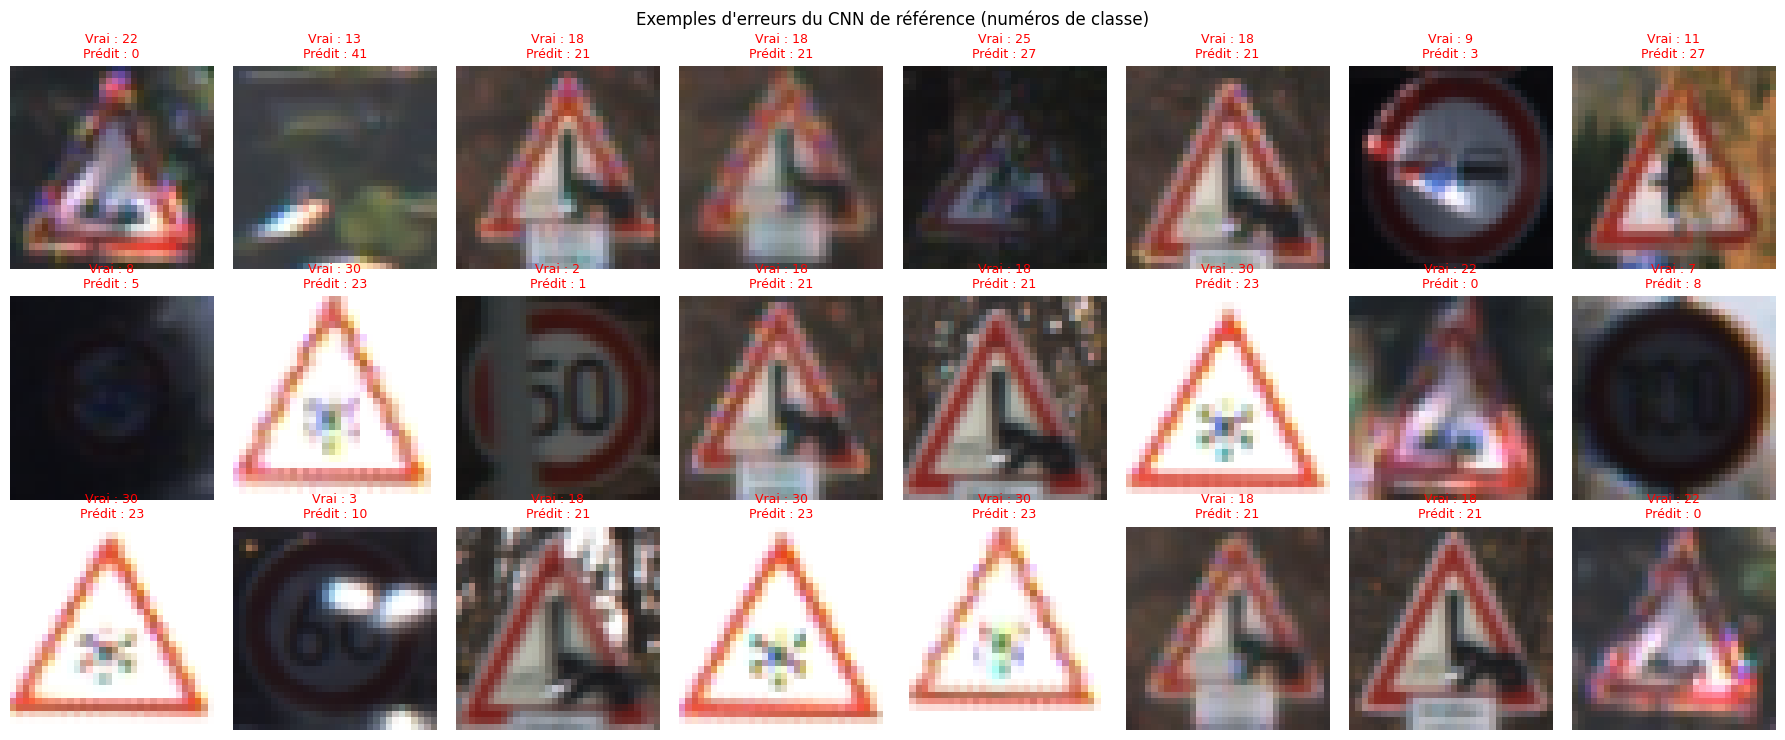

In [47]:
# 11. Analyse des erreurs du CNN
cm = confusion_matrix(y_test, y_pred_baseline)
off = cm.copy()
np.fill_diagonal(off, 0)

pairs = sorted(((off[i, j], i, j) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j] > 0),
               reverse=True)[:10]
errors = np.where(y_pred_baseline != y_test)[0]
print(f"{len(errors)} erreurs sur {len(y_test)} images\n\nLes 10 confusions les plus fréquentes :")
for n, i, j in pairs:
    print(f"  {n:3d} × {CLASS_NAMES[i]} ({i})  →  prédit : {CLASS_NAMES[j]} ({j})")

shown = np.random.default_rng(SEED).choice(errors, size=min(24, len(errors)), replace=False)
fig, axes = plt.subplots(3, 8, figsize=(18, 7.5))
for ax, idx in zip(axes.ravel(), shown):
    ax.imshow(X_test[idx]); ax.axis("off")
    ax.set_title(f"Vrai : {y_test[idx]}\nPrédit : {y_pred_baseline[idx]}", fontsize=9, color="red")
plt.suptitle("Exemples d'erreurs du CNN de référence (numéros de classe)")
plt.tight_layout(); plt.show()

# Partie B : détection des panneaux (GTSDB)

## 12. Téléchargement du jeu de détection GTSDB

**Pourquoi un second jeu de données ?** GTSRB ne contient que des panneaux **déjà découpés**. Pour apprendre à un détecteur à **trouver** les panneaux dans une scène, il faut des **photos complètes de routes** où chaque panneau est encadré : c'est le jeu **GTSDB**. Il vient de la même équipe et utilise **les mêmes 43 classes**, si bien que le CNN de la partie A pourra classer les panneaux détectés.

Le fichier `gt.txt` donne, pour chaque panneau : la photo, le cadre (`x1, y1, x2, y2`) et la classe.

**Statistiques :**

* **1 213 panneaux** dans 741 des 900 photos (les autres photos n'en contiennent aucun) ;
* les **43 classes** sont présentes ;
* **les panneaux sont petits** : largeur médiane de **38 pixels**, un quart font **moins de 28 pixels**, minimum 16 pixels, sur des photos de 1360 pixels de large.

Cette petite taille guide le choix de la résolution d'entraînement de YOLO (section 14).

In [50]:
# 12. Téléchargement du jeu de détection GTSDB (900 photos de routes annotées)
GTSDB_URL = "https://sid.erda.dk/public/archives/ff17dc924eba88d5d01a807357d6614c/FullIJCNN2013.zip"
GTSDB_DIR = "/content/FullIJCNN2013"

if not os.path.isdir(GTSDB_DIR):
    !wget -q --show-progress -O /content/gtsdb.zip {GTSDB_URL}
    !unzip -q /content/gtsdb.zip -d /content

gt = pd.read_csv(f"{GTSDB_DIR}/gt.txt", sep=";", header=None,
                 names=["file", "x1", "y1", "x2", "y2", "ClassId"])
gt["w"], gt["h"] = gt["x2"] - gt["x1"], gt["y2"] - gt["y1"]

print(f"Panneaux annotés : {len(gt)} | Photos contenant au moins un panneau : {gt['file'].nunique()} / 900")
print("Taille des panneaux en pixels (largeur) :", gt["w"].describe().round(1).to_dict())
print("Classes présentes :", gt["ClassId"].nunique(), "/ 43")

/content/gtsdb.zip  100%[===================>]   1.55G  24.8MB/s    in 2m 6s   
Panneaux annotés : 1213 | Photos contenant au moins un panneau : 741 / 900
Taille des panneaux en pixels (largeur) : {'count': 1213.0, 'mean': 43.6, 'std': 21.8, 'min': 16.0, '25%': 28.0, '50%': 38.0, '75%': 53.0, 'max': 127.0}
Classes présentes : 43 / 43


## 13. Conversion des annotations au format YOLO

**Une seule classe, `traffic_sign`.** Le détecteur doit seulement répondre à la question « où sont les panneaux ? » ; c'est le CNN qui dit lequel c'est. Ce découpage est justifié par deux raisons :

* avec seulement ~700 panneaux d'entraînement, un détecteur à 43 classes aurait trop peu d'exemples par classe ;
* le CNN, lui, a appris sur près de 40 000 images de panneaux.

**Séparation des photos :**

| Ensemble | Photos | Panneaux | Origine |
|---|---|---|---|
| Entraînement | 510 | 716 | photos 0 à 599, hors validation |
| Validation | 90 | 136 | tirées au hasard parmi les photos 0 à 599 |
| Test | 300 | 361 | photos 600 à 899 (séparation officielle de GTSDB) |

**Format YOLO :** une image et un fichier texte par photo. Chaque ligne du fichier décrit un panneau : `classe x_centre y_centre largeur hauteur`, avec des coordonnées **normalisées** entre 0 et 1. Les photos sans panneau ont un fichier vide : elles apprennent au modèle à ne rien détecter quand il n'y a rien. Le fichier `data.yaml` indique à YOLO où trouver chaque ensemble.

In [51]:
# 13. Conversion au format YOLO (une seule classe : "traffic_sign")
YOLO_DIR = "/content/gtsdb_yolo"
all_files = [f"{i:05d}.ppm" for i in range(900)]
train_pool, test_files = all_files[:600], all_files[600:]
val_files = set(np.random.default_rng(SEED).choice(train_pool, 90, replace=False))
splits = {"train": [f for f in train_pool if f not in val_files],
          "val": sorted(val_files), "test": test_files}

for split, files_ in splits.items():
    os.makedirs(f"{YOLO_DIR}/images/{split}", exist_ok=True)
    os.makedirs(f"{YOLO_DIR}/labels/{split}", exist_ok=True)
    for f in tqdm(files_, desc=split):
        img = Image.open(f"{GTSDB_DIR}/{f}").convert("RGB")
        W, H = img.size
        stem = f[:-4]
        img.save(f"{YOLO_DIR}/images/{split}/{stem}.jpg", quality=95)
        with open(f"{YOLO_DIR}/labels/{split}/{stem}.txt", "w") as fh:
            for b in gt[gt["file"] == f].itertuples():
                fh.write(f"0 {(b.x1 + b.x2) / 2 / W:.6f} {(b.y1 + b.y2) / 2 / H:.6f} "
                         f"{(b.x2 - b.x1) / W:.6f} {(b.y2 - b.y1) / H:.6f}\n")

with open(f"{YOLO_DIR}/data.yaml", "w") as fh:
    fh.write(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\n"
             "names:\n  0: traffic_sign\n")

for split, files_ in splits.items():
    n_boxes = gt["file"].isin(files_).sum()
    print(f"{split:5s} : {len(files_)} photos, {n_boxes} panneaux")

train:   0%|          | 0/510 [00:00<?, ?it/s]

val:   0%|          | 0/90 [00:00<?, ?it/s]

test:   0%|          | 0/300 [00:00<?, ?it/s]

train : 510 photos, 716 panneaux
val   : 90 photos, 136 panneaux
test  : 300 photos, 361 panneaux


## 14. Entraînement du détecteur YOLOv8s

* **Apprentissage par transfert :** on part des poids `yolov8s.pt`, pré-entraînés sur COCO (80 classes d'objets courants), puis on affine le modèle sur GTSDB.
* **Modèle *small* (YOLOv8s, 11 M de paramètres)** plutôt que *nano* : il est plus précis sur les petits objets, pour un coût raisonnable.
* **Résolution de 1280 pixels :** par défaut, YOLO réduit les images à 640 pixels. Les panneaux perdraient alors la moitié de leur taille, et les plus petits (16 pixels) n'en feraient plus que 8, ce qui les rendrait indétectables. En 1280, les photos gardent presque leur taille d'origine (1360).
* **100 epochs maximum, patience de 20** : arrêt automatique si la validation stagne.

**Résultat :** 100 epochs en **55 minutes** sur un GPU Tesla T4. En validation, précision 0,993, rappel 0,990, **mAP@0,5 = 0,995**. Les poids du meilleur modèle sont dans `weights/best.pt`.

In [54]:
# 14. Entraînement de YOLOv8s pour détecter les panneaux (une seule classe)
set_seed()
detector = YOLO("yolov8s.pt")
detector.train(
    data=f"{YOLO_DIR}/data.yaml",
    imgsz=1280,
    epochs=100,
    patience=20,
    batch=8,
    seed=SEED,
    project="/content/runs",
    name="gtsdb_yolov8s",
    exist_ok=True,
)

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/gtsdb_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=gtsdb_yolov8s, nbs=64, nms=None, opset=None, optimize=False,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7db945e39860>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

## 15. Évaluation du détecteur sur le test GTSDB

Le meilleur modèle est évalué sur les **300 photos de test** (361 panneaux) :

* **Précision** : part des détections qui sont vraiment des panneaux ;
* **Rappel** : part des vrais panneaux retrouvés ;
* **mAP@0,5** : mesure de référence en détection, qui résume la précision à tous les seuils de confiance. Une détection compte si son cadre recouvre au moins 50 % du vrai panneau (IoU ≥ 0,5) ;
* **mAP@0,5:0,95** : même mesure, moyennée sur des exigences de recouvrement de plus en plus strictes (IoU de 0,5 à 0,95). Elle mesure la **précision de placement** des cadres.

| Précision | Rappel | mAP@0,5 | mAP@0,5:0,95 |
|---|---|---|---|
| **0,990** | **0,981** | **0,993** | **0,897** |

Le détecteur trouve presque tous les panneaux. Un mAP@0,5:0,95 proche de 0,9 montre que ses cadres sont **très bien ajustés**, ce qui est important car le CNN classe exactement ce qui se trouve dans le cadre.

In [58]:
# 15. Évaluation du détecteur sur les 300 photos de test
detector = YOLO("/content/runs/gtsdb_yolov8s/weights/best.pt")
m = detector.val(data=f"{YOLO_DIR}/data.yaml", split="test", imgsz=1280, batch=8)
print(f"\nDétection sur le test GTSDB : précision {m.box.mp:.3f} | rappel {m.box.mr:.3f} "
      f"| mAP@0.5 {m.box.map50:.3f} | mAP@0.5:0.95 {m.box.map:.3f}")

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 74.3±57.3 MB/s, size: 359.9 KB)
val: Scanning /content/gtsdb_yolo/labels/test... 300 images, 65 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 468.3it/s 0.6s
val: New cache created: /content/gtsdb_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 3.1it/s 12.3s
                   all        300        361       0.99      0.981      0.993      0.897
Speed: 3.8ms preprocess, 30.7ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/runs/detect/val

Détection sur le test GTSDB : précision 0.990 | rappel 0.981 | mAP@0.5 0.993 | mAP@0.5:0.95 0.897


# Partie C : pipeline complet, résultats et export

## 16. Pipeline complet : YOLO détecte, le CNN classe

Pour chaque photo de test :

1. **YOLOv8s** détecte les panneaux (seuil de confiance de 0,5) ;
2. chaque cadre détecté est **découpé et redimensionné en 32×32**, comme les images GTSRB ;
3. le **CNN** prédit la classe de chaque découpe.

**Évaluation :** chaque vrai panneau est associé à la détection qui le recouvre le mieux (IoU ≥ 0,5). Une détection n'est **juste de bout en bout** que si le panneau est trouvé **et** correctement classé.

On isole aussi l'effet de chaque étape. Le CNN est évalué sur les **cadres annotés à la main** (sans YOLO), puis sur les **cadres trouvés par YOLO**.

| Mesure | Résultat |
|---|---|
| Détections / panneaux réels | 374 / 361 |
| Détection : rappel / précision | 99,2 % / 95,7 % |
| CNN sur les cadres annotés | 100 % (361 / 361) |
| CNN sur les cadres de YOLO | 99,7 % |
| **Bout en bout : rappel / précision** | **98,9 % / 95,5 %** |

**Lecture :**

* Le CNN, entraîné sur GTSRB, **se transfère très bien** aux panneaux de GTSDB, et les cadres de YOLO ne dégradent presque pas la classification.
* Le score de 100 % est à relativiser :
  * il porte sur seulement 361 panneaux ;
  * les panneaux de GTSDB sont en moyenne plus nets que les cas difficiles du test GTSRB ;
  * les deux jeux ayant été enregistrés par la même équipe, certains panneaux physiques pourraient apparaître dans les deux.
* Le rappel diffère légèrement de la section 15 (0,992 contre 0,981), car le **seuil de confiance** n'est pas le même : 0,5 fixe ici, choisi automatiquement par Ultralytics en section 15.

In [59]:
# 16. Pipeline complet : YOLO trouve les panneaux, le CNN les classe
CONF = 0.5        # seuil de confiance de YOLO
IOU_MATCH = 0.5   # une détection est juste si elle recouvre au moins 50 % du vrai panneau

def crop_signs(img, boxes, size=IMG_SIZE):
    crops = [np.asarray(img.crop(tuple(int(round(v)) for v in b)).resize((size, size), Image.BILINEAR))
             for b in boxes]
    return np.stack(crops) if crops else np.empty((0, size, size, 3), np.uint8)

def detect_and_classify(img, conf=CONF):
    r = detector.predict(img, imgsz=1280, conf=conf, verbose=False)[0]
    boxes = r.boxes.xyxy.cpu().numpy()          # triées par confiance décroissante
    scores = r.boxes.conf.cpu().numpy()
    if len(boxes) == 0:
        return boxes, scores, np.array([], dtype=int)
    cls = baseline.predict(crop_signs(img, boxes), verbose=0).argmax(axis=1)
    return boxes, scores, cls

def iou(a, b):
    x1, y1, x2, y2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)

test_files = [f"{i:05d}.ppm" for i in range(600, 900)]
gt_test = gt[gt["file"].isin(test_files)].reset_index(drop=True)

rows, preds_by_file, n_det = [], {}, 0
for f in tqdm(test_files):
    img = Image.open(f"{GTSDB_DIR}/{f}").convert("RGB")
    boxes, scores, cls = detect_and_classify(img)
    preds_by_file[f] = (boxes, scores, cls)
    n_det += len(boxes)
    used = set()
    for s in gt_test[gt_test["file"] == f].itertuples():
        best_j, best_iou = -1, IOU_MATCH
        for j, b in enumerate(boxes):
            v = iou((s.x1, s.y1, s.x2, s.y2), b)
            if j not in used and v >= best_iou:
                best_j, best_iou = j, v
        if best_j >= 0:
            used.add(best_j)
        rows.append({"file": f, "true": s.ClassId, "detected": best_j >= 0,
                     "pred": cls[best_j] if best_j >= 0 else -1})

ev = pd.DataFrame(rows)
n_gt, tp_det = len(ev), int(ev["detected"].sum())
tp_full = int((ev["detected"] & (ev["true"] == ev["pred"])).sum())

# Contrôle : le CNN seul sur les vrais cadres GTSDB (sans l'effet de YOLO)
X_gt = np.stack([crop_signs(Image.open(f"{GTSDB_DIR}/{s.file}").convert("RGB"),
                            [(s.x1, s.y1, s.x2, s.y2)])[0] for s in gt_test.itertuples()])
acc_gt_crops = float((baseline.predict(X_gt, verbose=0).argmax(1) == gt_test["ClassId"]).mean())

results["pipeline"] = {
    "detection_recall": tp_det / n_gt, "detection_precision": tp_det / n_det,
    "cls_acc_on_detected": tp_full / tp_det, "cnn_acc_on_gt_crops": acc_gt_crops,
    "e2e_recall": tp_full / n_gt, "e2e_precision": tp_full / n_det,
}
print(f"Panneaux réels : {n_gt} | détections : {n_det} | fausses détections : {n_det - tp_det}")
print(f"Détection            : rappel {tp_det/n_gt:.3f} | précision {tp_det/n_det:.3f}")
print(f"CNN sur cadres réels : {acc_gt_crops:.3f}")
print(f"CNN sur cadres YOLO  : {tp_full/tp_det:.3f}")
print(f"Bout en bout         : rappel {tp_full/n_gt:.3f} | précision {tp_full/n_det:.3f}")

  0%|          | 0/300 [00:00<?, ?it/s]

Panneaux réels : 361 | détections : 374 | fausses détections : 16
Détection            : rappel 0.992 | précision 0.957
CNN sur cadres réels : 1.000
CNN sur cadres YOLO  : 0.997
Bout en bout         : rappel 0.989 | précision 0.955


## 17. Démonstration du pipeline et analyse de ses erreurs

**Démonstration :** 6 scènes de test contenant au moins deux panneaux. Les **cadres verts** sont les détections, avec la classe prédite par le CNN et la confiance de YOLO ; les **pointillés jaunes** sont les annotations réelles.

**Fausses détections (16).** Leur examen montre qu'environ **12 d'entre elles sont de vrais panneaux** qui n'appartiennent pas aux 43 classes, et ne sont donc pas annotés dans GTSDB :

* arrêt de bus ;
* interdictions de stationner ;
* pistes cyclables et piétonnes ;
* panneau de direction.

Les vraies erreurs se limitent à 3 ou 4 objets ronds ressemblant à des panneaux : une boule réfléchissante et l'arrière d'un camion-citerne, vu sur deux images. Le détecteur est donc meilleur que ne l'indique sa précision.

Cela révèle la **principale limite du système**. Le CNN n'a pas de classe « autre panneau » : il range obligatoirement tout panneau inconnu dans l'une des 43 classes (par exemple, l'arrêt de bus devient « Ahead only »).

**Panneaux manqués ou mal classés :**

* **3 panneaux manqués**, tous petits : 16, 21 et 30 pixels de large. La photo 00646 contient deux « Yield » de la même classe : l'affichage les liste tous les deux, alors qu'un seul a été manqué.
* **1 panneau mal classé** : un « Priority road » reconnu comme « No vehicles ». C'est la même confusion que sur GTSRB (section 11).

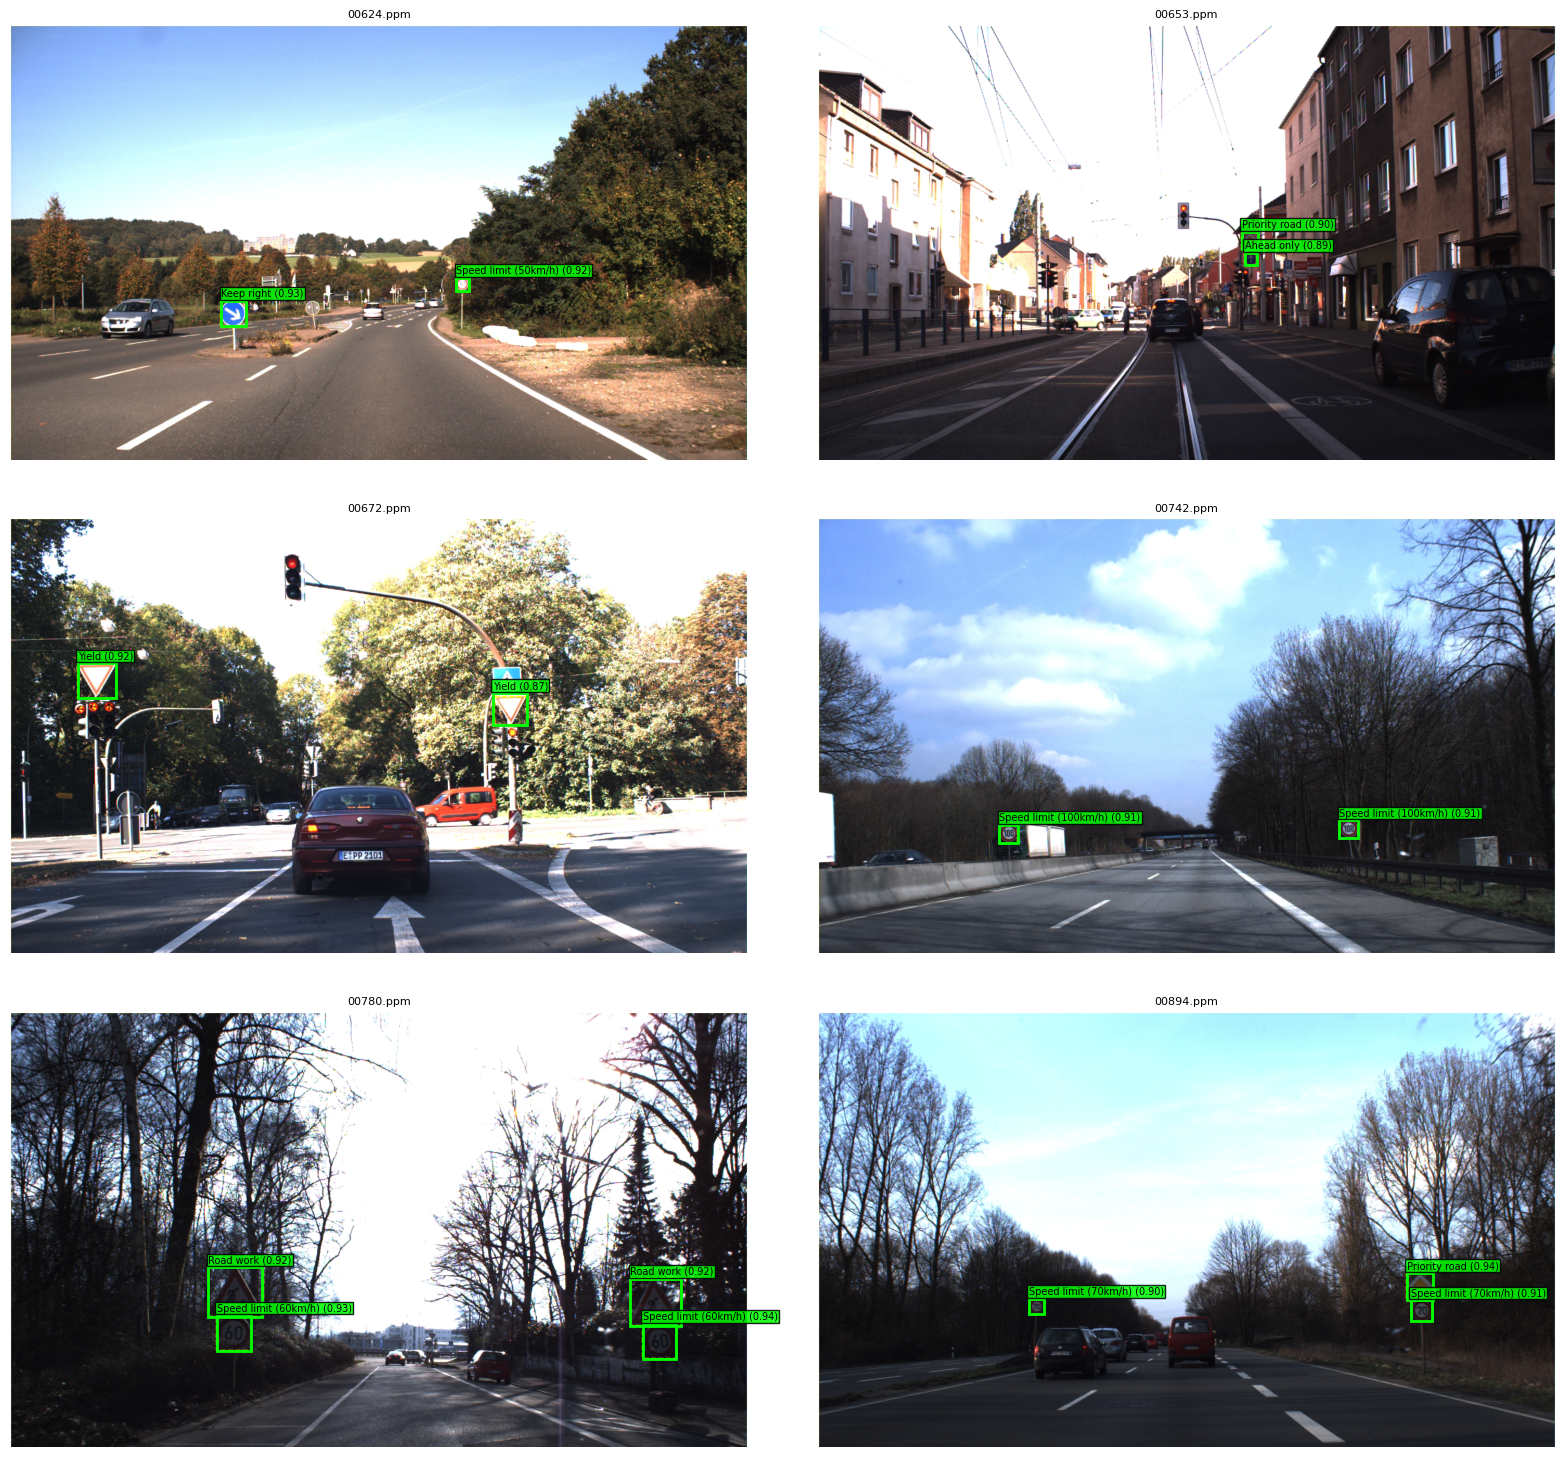

16 fausses détections


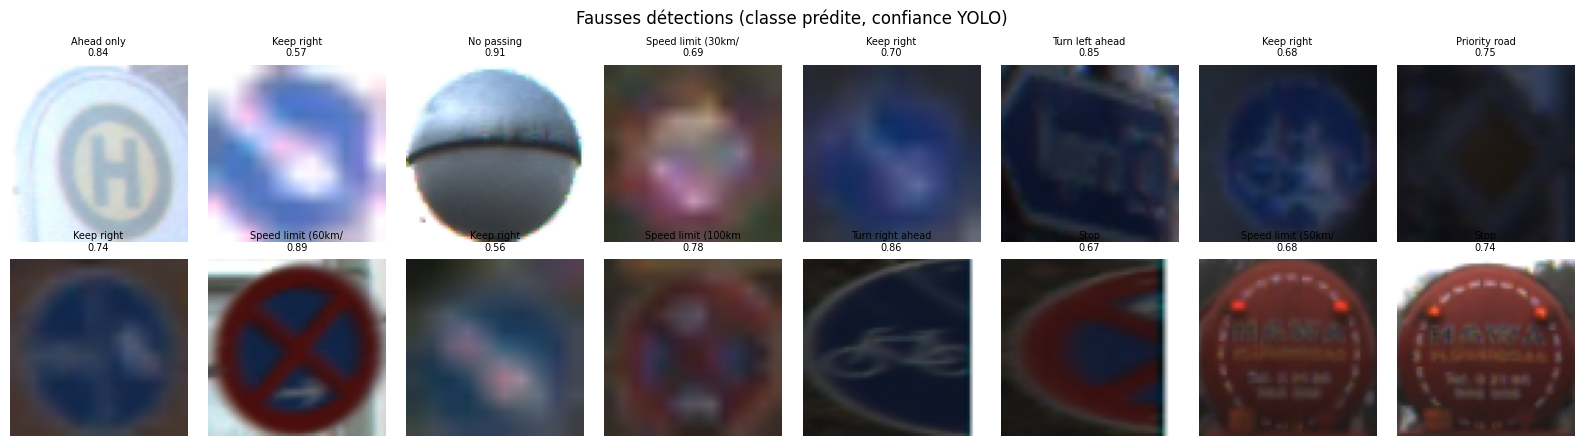

00646.ppm | Yield | largeur 31px | manqué
00646.ppm | Yield | largeur 30px | manqué
00668.ppm | Priority road | largeur 117px | classé No vehicles
00725.ppm | Keep left | largeur 21px | manqué
00787.ppm | General caution | largeur 16px | manqué


In [61]:
# 17. Démonstration du pipeline et analyse de ses erreurs
FIG_DIR = "/content/figures"; os.makedirs(FIG_DIR, exist_ok=True)
open_rgb = lambda f: Image.open(f"{GTSDB_DIR}/{f}").convert("RGB")

def show_scene(f, ax):
    boxes, scores, cls = preds_by_file[f]
    ax.imshow(open_rgb(f)); ax.axis("off"); ax.set_title(f, fontsize=8)
    for s in gt_test[gt_test["file"] == f].itertuples():      # vérité terrain en pointillés jaunes
        ax.add_patch(patches.Rectangle((s.x1, s.y1), s.x2 - s.x1, s.y2 - s.y1,
                                       fill=False, ec="yellow", lw=1, ls="--"))
    for b, sc, c in zip(boxes, scores, cls):                    # prédictions en vert
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=2))
        ax.text(b[0], b[1] - 8, f"{CLASS_NAMES[c]} ({sc:.2f})", fontsize=7,
                bbox=dict(fc="lime", alpha=0.85, pad=1))

# Démonstration : 6 scènes contenant au moins 2 panneaux
multi = gt_test["file"].value_counts()
demo = sorted(random.Random(SEED).sample(list(multi[multi >= 2].index), 6))
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
for f, ax in zip(demo, axes.ravel()):
    show_scene(f, ax)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/pipeline_demo.png", dpi=120, bbox_inches="tight"); plt.show()

# Fausses détections : cadres YOLO qui ne recouvrent aucun panneau annoté
fps = []
for f, (boxes, scores, cls) in preds_by_file.items():
    g = gt_test[gt_test["file"] == f][["x1", "y1", "x2", "y2"]].to_numpy()
    for b, sc, c in zip(boxes, scores, cls):
        if all(iou(gb, b) < IOU_MATCH for gb in g):
            fps.append((f, b, sc, c))
print(f"{len(fps)} fausses détections")
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax in axes.ravel(): ax.axis("off")
for (f, b, sc, c), ax in zip(fps, axes.ravel()):
    ax.imshow(crop_signs(open_rgb(f), [b], size=64)[0])
    ax.set_title(f"{CLASS_NAMES[c][:18]}\n{sc:.2f}", fontsize=7)
plt.suptitle("Fausses détections (classe prédite, confiance YOLO)"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/pipeline_false_positives.png", dpi=120, bbox_inches="tight"); plt.show()

# Panneaux manqués ou mal classés
bad = ev[~ev["detected"] | (ev["true"] != ev["pred"])].merge(gt_test, on=["file"], how="left")
bad = bad[bad["true"] == bad["ClassId"]].drop_duplicates(subset=["file", "x1", "y1"])
for s in bad.itertuples():
    status = "manqué" if not s.detected else f"classé {CLASS_NAMES[s.pred]}"
    print(f"{s.file} | {CLASS_NAMES[s.true]} | largeur {s.x2 - s.x1}px | {status}")

## 18. Figures, métriques et export

Cette dernière cellule rassemble les résultats du projet dans une archive `traffic_sign_detection_recognition.zip` :

* **Figures** :
  * courbes d'apprentissage du CNN ;
  * matrice de confusion du test GTSRB, avec le nombre d'images par case (les erreurs en rouge) ;
  * exemples de prédictions ;
  * scènes de démonstration ;
  * courbes d'entraînement et courbe précision-rappel de YOLO.
* **`metrics.json`** : toutes les métriques (CNN, détecteur, pipeline complet) ;
* **Modèles** :
  * `gtsrb_cnn_classifier.keras`, le classifieur (21 Mo) ;
  * `gtsdb_yolov8s_detector.pt`, le détecteur (23 Mo).

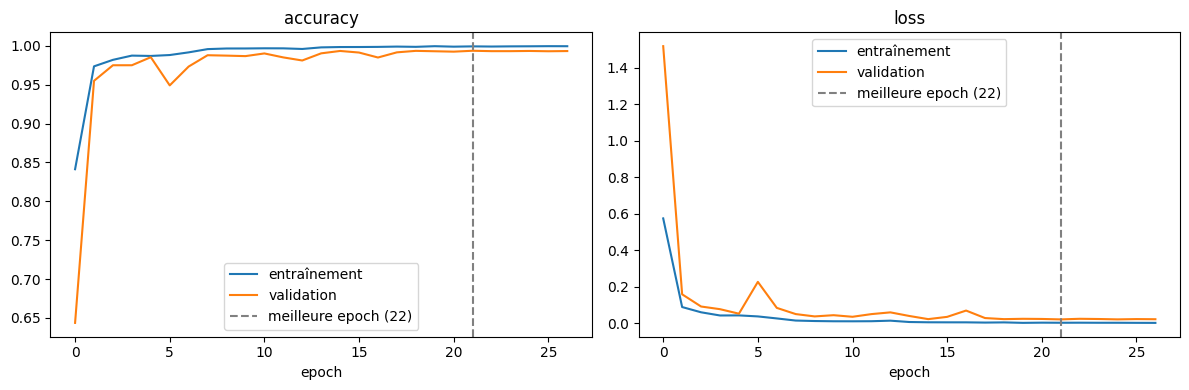

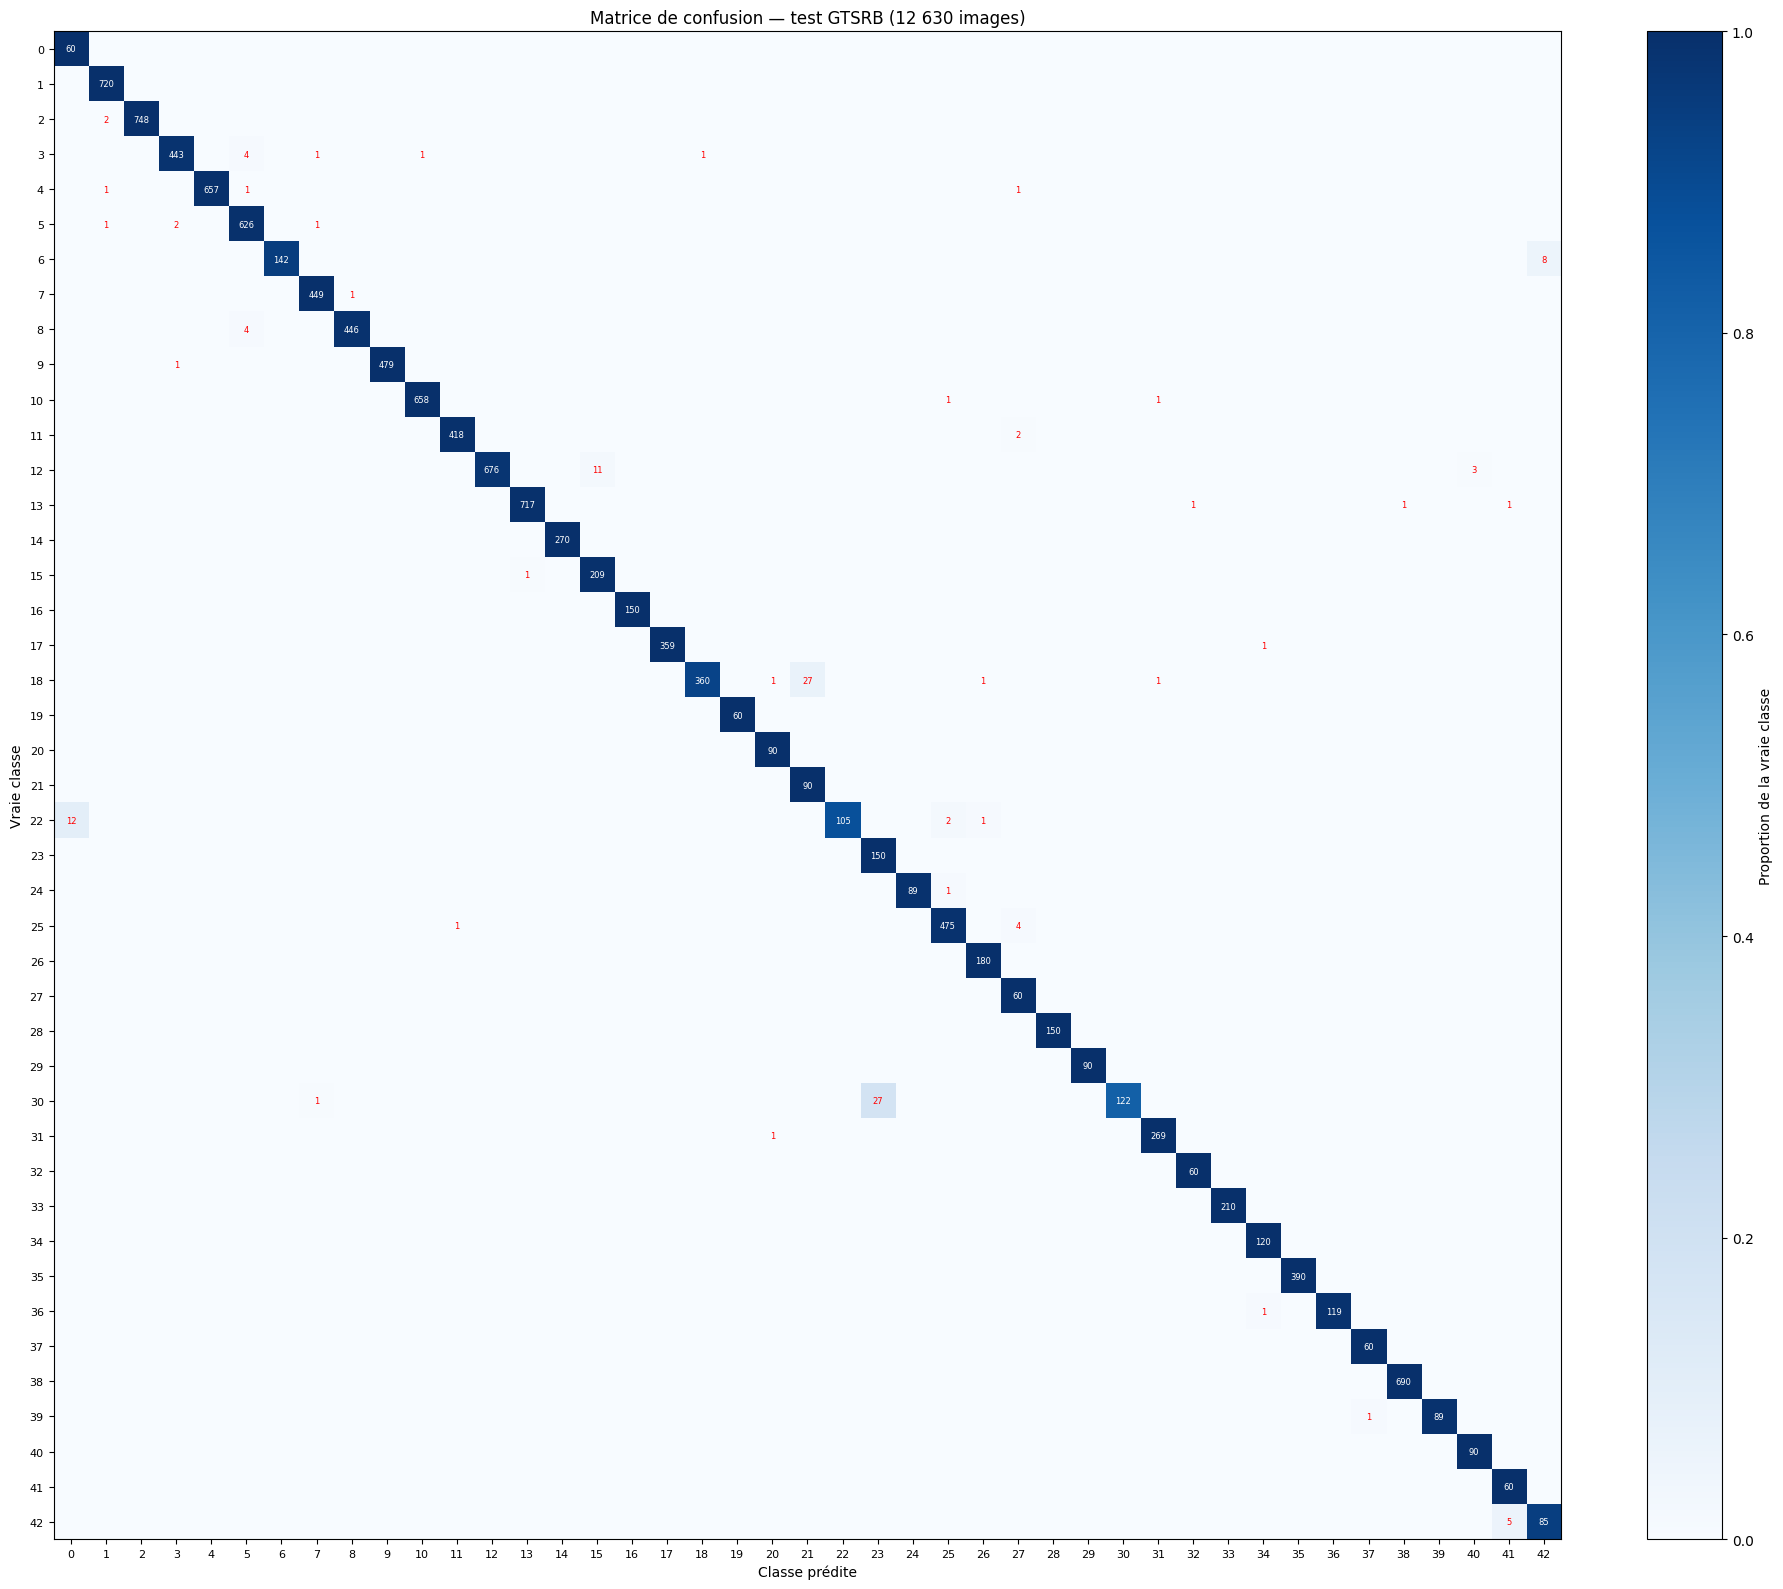

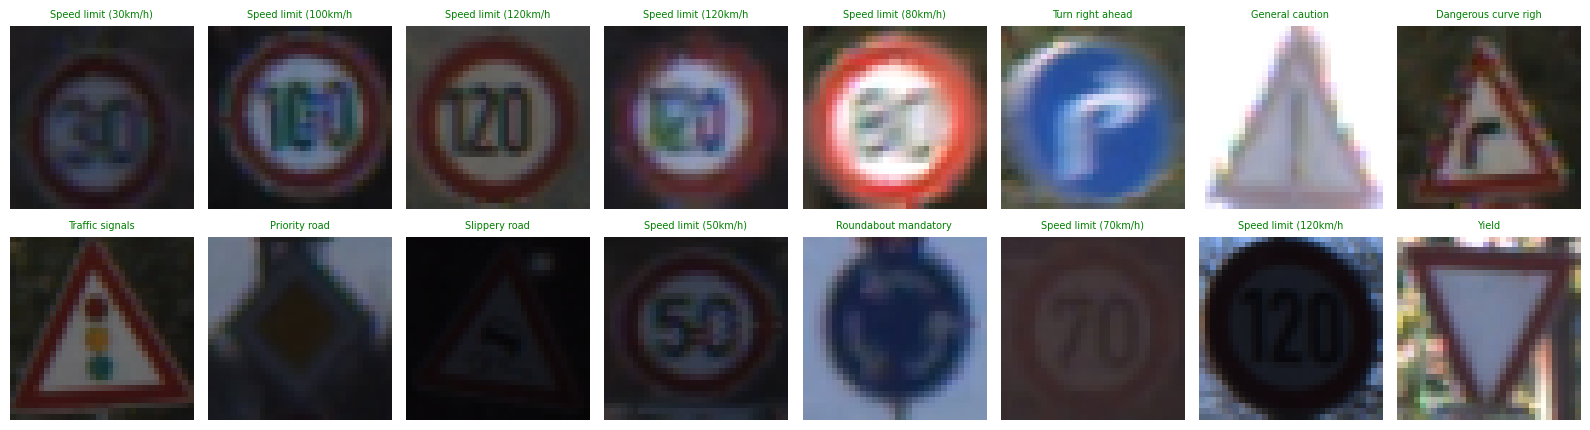

{
  "baseline_cnn": {
    "test_accuracy": 0.9889152646064758,
    "test_loss": 0.04533861204981804,
    "macro_f1": 0.9792619976077069,
    "best_epoch": 22,
    "val_accuracy": 0.9937419891357422,
    "val_loss": 0.02055244892835617
  },
  "pipeline": {
    "detection_recall": 0.9916897506925207,
    "detection_precision": 0.9572192513368984,
    "cls_acc_on_detected": 0.9972067039106145,
    "cnn_acc_on_gt_crops": 1.0,
    "e2e_recall": 0.9889196675900277,
    "e2e_precision": 0.9545454545454546
  },
  "yolo_detector": {
    "precision": 0.9896013057987,
    "recall": 0.9806094182825484,
    "mAP50": 0.9927106038613451,
    "mAP50_95": 0.8971206704894163
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [66]:
# 18. Figures, métriques et export
ART_DIR = "/content/artifacts"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(ART_DIR, exist_ok=True)

# Courbes d'apprentissage du CNN
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key in zip(axes, ["accuracy", "loss"]):
    ax.plot(history.history[key], label="entraînement")
    ax.plot(history.history[f"val_{key}"], label="validation")
    ax.axvline(best, ls="--", c="gray", label=f"meilleure epoch ({best + 1})")
    ax.set_title(key); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/training_curves.png", dpi=120, bbox_inches="tight"); plt.show()

# Matrice de confusion (test GTSRB) : couleur = proportion par vraie classe, nombre = effectif
cm = confusion_matrix(y_test, y_pred_baseline)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i, j in zip(*np.nonzero(cm)):
    ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
            color="white" if cm_norm[i, j] > 0.5 else ("red" if i != j else "black"))
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.tick_params(labelsize=8); ax.set_xlabel("Classe prédite"); ax.set_ylabel("Vraie classe")
fig.colorbar(im, fraction=0.046, label="Proportion de la vraie classe")
ax.set_title("Matrice de confusion — test GTSRB (12 630 images)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

# Exemples de prédictions sur le test GTSRB (rouge = erreur)
idx = np.random.default_rng(SEED).choice(len(X_test), 16, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i, ax in zip(idx, axes.ravel()):
    ok = y_pred_baseline[i] == y_test[i]
    ax.imshow(X_test[i]); ax.axis("off")
    ax.set_title(CLASS_NAMES[y_pred_baseline[i]][:20], fontsize=7, color="green" if ok else "red")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/predictions.png", dpi=120, bbox_inches="tight"); plt.show()

# Métriques
results["baseline_cnn"].update({"best_epoch": best + 1,
                                "val_accuracy": history.history["val_accuracy"][best],
                                "val_loss": history.history["val_loss"][best]})
results["yolo_detector"] = {"precision": m.box.mp, "recall": m.box.mr,
                            "mAP50": m.box.map50, "mAP50_95": m.box.map}
with open(f"{ART_DIR}/metrics.json", "w") as fh:
    json.dump(results, fh, indent=2, default=float)
print(json.dumps(results, indent=2, default=float))

# Modèles, figures et courbes YOLO
RUN_DIR = "/content/runs/gtsdb_yolov8s"
shutil.copy(f"{MODEL_DIR}/gtsrb_cnn_classifier.keras", ART_DIR)
shutil.copy(f"{RUN_DIR}/weights/best.pt", f"{ART_DIR}/gtsdb_yolov8s_detector.pt")
for name in os.listdir(RUN_DIR):
    if name == "results.png" or name.endswith("PR_curve.png"):
        shutil.copy(f"{RUN_DIR}/{name}", f"{FIG_DIR}/yolo_{name}")
shutil.copytree(FIG_DIR, f"{ART_DIR}/figures", dirs_exist_ok=True)

shutil.make_archive("/content/traffic_sign_detection_recognition", "zip", ART_DIR)
from google.colab import files
files.download("/content/traffic_sign_detection_recognition.zip")

## Conclusion

Ce projet aboutit à un système de reconnaissance des panneaux routiers en deux étapes, évalué sur de vraies scènes de route :

* le **CNN** atteint **98,89 %** d'accuracy sur le test GTSRB, avec une validation séparée **par panneau physique** pour éviter toute fuite de données ;
* le **détecteur YOLOv8s** atteint un **mAP@0,5 de 0,993** sur le test GTSDB, grâce à un entraînement en haute résolution adapté aux petits panneaux ;
* le **pipeline complet** retrouve et identifie correctement **98,9 %** des panneaux, avec **95,5 %** de détections justes.

### Limites

* **Ensemble fermé de 43 classes :** les panneaux hors de ces classes sont détectés puis forcément classés dans l'une d'elles.
* **Panneaux très petits :** les rares panneaux manqués font entre 16 et 30 pixels de large.
* **Test de détection limité :** 300 photos et 361 panneaux, tous allemands. Les performances sur d'autres pays ou d'autres caméras restent à vérifier.

### Pistes d'amélioration

* Rejeter les panneaux inconnus, grâce à un seuil sur la confiance du CNN ou à une classe « autre ».
* Mieux détecter les très petits panneaux, par exemple en découpant l'image en tuiles.
* Évaluer le système sur un jeu plus varié (autres pays, nuit, pluie).